In [1]:
import pandas as pd   
import numpy as np       
import matplotlib.pyplot as plt 
from pathlib import Path 

In [ ]:
# load data 
BASE_DIR = Path().cwd().parent
DATA_DIR = BASE_DIR / "teachpandas" / "sample_drone_flights.csv"

if not DATA_DIR.exists():
    raise FileExistsError("Data Doesn't exist")
if not DATA_DIR.suffix in [".csv", ".xlsx"]:
    raise TypeError("Expected File Type Missing")

df = pd.read_csv(DATA_DIR)
if len(set(df.columns)) != len(df.columns):
    print("Data has duplicated columns\n"
          "Dropping Duplicate Columns ...")
    df = df.loc[:, df.columns.drop_duplicates()]
    
df.columns = df.columns.str.strip()

selected_cols = [
        "datetime(utc)",
        "time(millisecond)",
        "flycState",
        'current(A)',
        "battery_temperature(f)",
        "speed(mph)",
        "voltage(v)",
        "longitude",
        "latitude",
    ]

missing = [col for col in selected_cols if col not in df.columns]
if missing:
    raise ValueError(f"Missing Expected Columns: {missing}")
for col in [col for col in df.columns if "date" in col]:
    df[col] = pd.to_datetime(df[col])
    
df_new = df[selected_cols]

In [ ]:
drop_cols = list(df_new.columns[df_new.columns.str.contains("longitude|latitude|millisecond")])
df_model = df_new.drop(columns=drop_cols)

new_data = {}
for state in  df_model["flycState"].unique():
    new_data[state] = df_model[df_model["flycState"] == state]
    
plt.figure(figsize=(6,4))
plt.plot(df_model["datetime(utc)"], df_model["battery_temperature(f)"])
plt.xlabel("Date Time")
plt.ylabel("Battery Temperature")
plt.title("Time vs Battery Temperature During UAV Flights")
plt.grid(color="gray", alpha=0.1,)
plt.show()

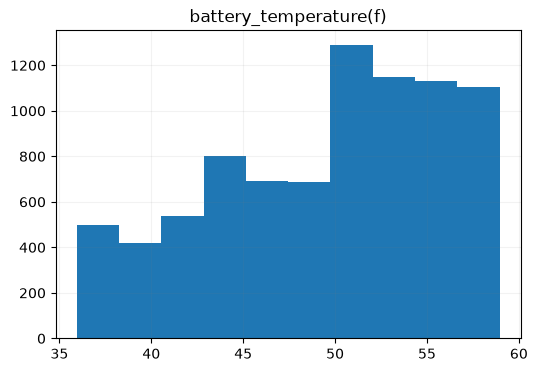

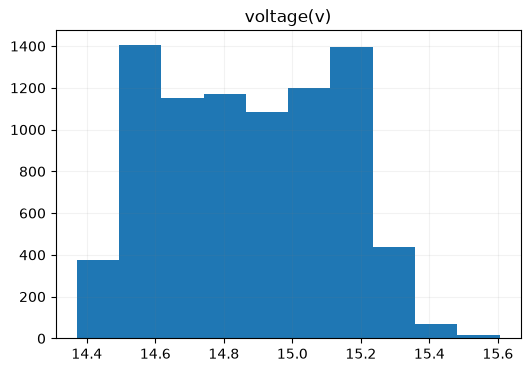

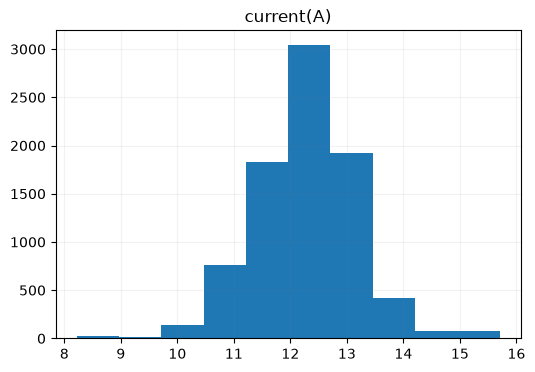

In [74]:
df_waypoint = new_data["Waypoint"]
for label in ["battery_temperature(f)", "voltage(v)", "current(A)"]:
    plt.figure(figsize=(6,4))
    plt.hist(x=df_waypoint[label], bins=10)
    plt.title(f"{label}")
    plt.grid(color="gray", alpha=0.1)
plt.show()

In [ ]:
df_model = df_model.sort_values(by="datetime(utc)")
df_final = df_model.drop(columns=["flycState"])

In [ ]:
# build model
from xgboost import XGBRegressor
from pipeline import pipeline
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, TimeSeriesSplit
from sklearn.preprocessing import StandardScaler

model = XGBRegressor(random_state=42,
                     n_estimates=100)
pipe = Pipeline(steps=[("scaler", StandardScaler()),
                       ("model", model)]
                        )

X = df_final.drop(columns=["datetime(utc)", "battery_temperatue(f)"])
y = pd.to_numeric(df_final["battery_temperature(f)"], errors="coerce")



In [75]:
df_final

,datetime(utc),current(A),battery_temperature(f),speed(mph),voltage(v)
0,2019-05-17 15:08:13,14.714,35.95001,-0.600001,15.497
1,2019-05-17 15:08:13,14.714,35.95001,-0.600001,15.497
2,2019-05-17 15:08:13,14.714,35.95001,-0.600001,15.497
3,2019-05-17 15:08:13,14.714,35.95001,-0.800001,15.497
4,2019-05-17 15:08:13,14.714,35.95001,-1.000002,15.497
...,...,...,...,...,...
9610,2019-05-17 15:24:15,13.126,61.95002,0.000000,14.371
9611,2019-05-17 15:24:15,13.126,61.95002,0.000000,14.371
9612,2019-05-17 15:24:15,13.126,61.95002,0.000000,14.371
9613,2019-05-17 15:24:15,13.126,61.95002,0.000000,14.371
